# What our data is about:
Solvability measures how much of a compound can dissolve in water at a given pH and temperature, directly dictating a drug's oral bioavailability and absorption potential. Poor solubility limits how fast a drug can dissolve in gastrointestinal tract, impacting drug's performance and usefulness. Some low-solubility compounds can require specialized formulation strategies, to target specific delivery sytem in the organism that we want to achieve.

We have a lot of continous and binary features, as will be shown in EDA below. Our best guess for their meaning is that we have normalized 1D/2D Molecular Descriptors - structural properties calculated by chemical libraries. 

We have 48 binary features representing structural fingerprints like the presence or absence of specific rings, bonds, or functional groups 
and 248 continuous features representing global physical properties like molecular weight, total polar surface area, or lipophilicity.


Knowing we are working with ADMET property and molecular descriptors, we will approach the data with caution, knowing that some features may be extremly important, while being an outlier for example.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotx
import seaborn as sns
import plotly.express as px
import umap
import optuna

from scipy.stats import f_oneway
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.ensemble import IsolationForest
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from catboost import CatBoostRegressor

from xgboost import XGBClassifier
from catboost import CatBoostClassifier

style = matplotx.styles.gruvbox["light"]
plt.style.use(style)
# plt.rcParams.update({
#     "figure.facecolor": "white",  # outside the axes
#     "axes.facecolor": "white",    # plot area
#     "savefig.facecolor": "white", # saved images
# })


from sklearn.metrics import root_mean_squared_error, make_scorer
from sklearn.compose import ColumnTransformer
import xgboost as xgb
import lightgbm as lgb
from IPython.display import display
import warnings

# EDA

In [39]:

training_data = pd.read_csv("../../challenge/TrainingData_Blinded.csv", header=0, index_col="Name")
test_df = pd.read_csv("../../challenge/TestData_Blinded_NoY.csv", header=0, index_col="Name")


training_data.rename(columns={'Y': 'target'}, inplace=True)
X = training_data.drop(columns=["target"]).copy()
y = training_data["target"]

print("Dataset shape:", training_data.shape)
print("Number of classes:", y.nunique())

training_data.head()

Dataset shape: (1087, 296)
Number of classes: 338


,target,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X330,X331,X332,X333,X334,X335,X336,X337,X338,X339
Name,,,,,,,,,,,,,,,,,,,,,
Y1,-0.085199,0.309546,0.755618,0.0,0.029666,0.128079,0,0.0,0.098216,0.062834,...,0.000,0.000000,0,0.000000,0.159079,0.0,0,0.000000,0,0.0
Y2,-0.353311,0.288419,0.528816,0.0,0.090244,0.069176,0,0.0,0.102855,0.081353,...,0.125,0.000000,0,0.077361,0.102335,0.0,0,0.000000,0,0.0
Y3,0.933576,0.419655,0.775678,0.0,0.147795,0.231356,0,0.0,0.192243,0.102755,...,0.000,0.000000,0,0.941991,0.266956,0.0,0,0.000000,0,0.0
Y5,0.071583,0.455953,0.621974,0.0,0.016421,0.042072,0,0.0,0.067610,0.046155,...,0.000,0.248861,0,0.202801,0.079247,0.0,0,0.333333,0,0.0
Y6,-0.389871,0.328753,0.569900,0.0,0.150318,0.040787,1,0.0,0.132359,0.083607,...,0.250,0.237481,0,0.124486,0.121555,0.0,0,0.000000,0,0.0


In [40]:
training_data.describe()

,target,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X330,X331,X332,X333,X334,X335,X336,X337,X338,X339
count,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,...,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000
mean,0.004513,0.324930,0.598499,0.004600,0.092906,0.096465,0.023919,0.007820,0.132674,0.092115,...,0.050943,0.056610,0.027599,0.134391,0.155980,0.009972,0.004600,0.016559,0.031279,0.002883
std,0.315469,0.127109,0.112948,0.052357,0.101186,0.113275,0.152867,0.072343,0.088995,0.084020,...,0.098945,0.136687,0.163896,0.176417,0.103498,0.062025,0.067697,0.086610,0.174150,0.041849
min,-0.713205,0.000000,-0.045405,0.000000,0.000000,0.000000,0.000000,0.000000,0.006862,0.000000,...,0.000000,-0.007090,0.000000,-0.001502,0.004104,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-0.256138,0.248555,0.540171,0.000000,0.028135,0.020824,0.000000,0.000000,0.083894,0.046002,...,0.000000,0.000000,0.000000,0.000000,0.095754,0.000000,0.000000,0.000000,0.000000,0.000000
50%,-0.022415,0.303300,0.608965,0.000000,0.066682,0.072494,0.000000,0.000000,0.112968,0.077890,...,0.000000,0.000000,0.000000,0.049144,0.135002,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.212094,0.369575,0.668921,0.000000,0.134380,0.131796,0.000000,0.000000,0.149047,0.112930,...,0.125000,0.000000,0.000000,0.227662,0.177760,0.000000,0.000000,0.000000,0.000000,0.000000
max,0.950096,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


We can see that the values are normalized in some way, either using min-max scaler or z-score scaler. We are suspecting that the dataset was scaled based on some larger chemical dataset. This way the properties of the compounds are preserved and the model is not biased to the subset chosen for training, but represent larger group of compounds and chemical properties. 

In [41]:
# 1. Missing Values Analysis
missing_counts = X.isnull().sum()
total_missing = missing_counts.sum()
print(f"Total missing values in dataset: {total_missing}")

if total_missing > 0:
    missing_features = missing_counts[missing_counts > 0].sort_values(ascending=False)
    plt.figure(figsize=(10, 4))
    sns.barplot(x=missing_features.index, y=missing_features.values, color="salmon")
    plt.title("Missing Values per Feature")
    plt.ylabel("Missing Count")
    plt.xticks(rotation=90)
    plt.show()

Total missing values in dataset: 0


In [42]:
stats = pd.DataFrame({
    "mean": training_data.mean(),
    "median": training_data.median(),
    "mode": training_data.mode().iloc[0],
    "range": training_data.max() - training_data.min(),
    "std": training_data.std(),
    "cv": training_data.std() / training_data.mean(),
    "iqr": training_data.quantile(0.75) - training_data.quantile(0.25),
    "skewness": training_data.skew(),
    "kurtosis": training_data.kurt()
})

stats

,mean,median,mode,range,std,cv,iqr,skewness,kurtosis
target,0.004513,-0.022415,0.020277,1.663301,0.315469,69.908689,0.468232,0.425750,-0.396715
X1,0.324930,0.303300,0.000000,1.000000,0.127109,0.391190,0.121020,1.269164,5.001758
X2,0.598499,0.608965,0.703054,1.045405,0.112948,0.188718,0.128750,-0.439118,0.922465
X3,0.004600,0.000000,0.000000,1.000000,0.052357,11.382407,0.000000,12.590393,177.330019
X4,0.092906,0.066682,0.000000,1.000000,0.101186,1.089126,0.106245,3.130676,16.982691
...,...,...,...,...,...,...,...,...,...
X335,0.009972,0.000000,0.000000,1.000000,0.062025,6.219761,0.000000,8.207443,87.460925
X336,0.004600,0.000000,0.000000,1.000000,0.067697,14.717312,0.000000,14.662804,213.390429
X337,0.016559,0.000000,0.000000,1.000000,0.086610,5.230273,0.000000,6.044707,41.698307
X338,0.031279,0.000000,0.000000,1.000000,0.174150,5.567684,0.000000,5.392877,27.133038


## Understanding target variable

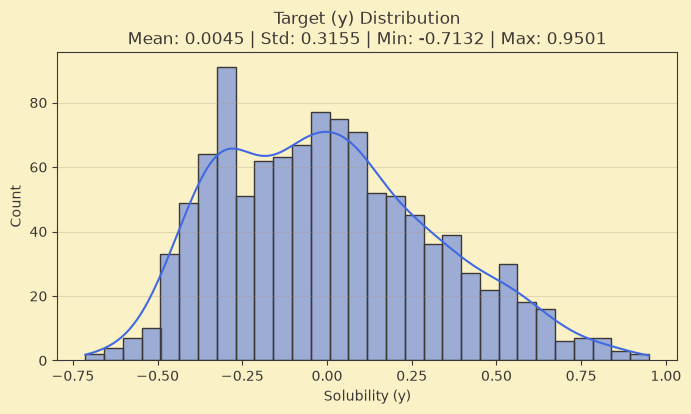

In [43]:
plt.figure(figsize=(8, 4))
sns.histplot(y, kde=True, bins=30, color='royalblue')
plt.title(f"Target (y) Distribution\nMean: {y.mean():.4f} | Std: {y.std():.4f} | Min: {y.min():.4f} | Max: {y.max():.4f}")
plt.xlabel("Solubility (y)")
plt.ylabel("Count")
plt.grid(axis='y', alpha=0.3)
plt.show()

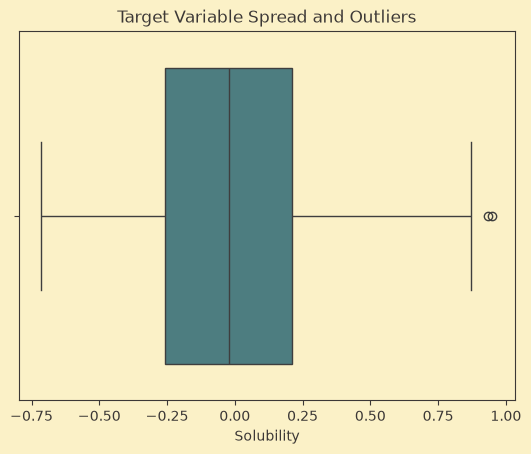

In [44]:
sns.boxplot(x=training_data['target'])
plt.title("Target Variable Spread and Outliers")
plt.xlabel("Solubility")
plt.show()

Based on the histogram, kernel density estimation, boxplot and the statistics calculated above, we can see that the target variable has small right skew (0.42) and kurtosis (-0.40). It follows from the bimodal distribution that we observe. The distribution focuses on values around -0.3 and 0.0. This means we have mostly weak solubility and ok solubility. We do not have a clear distinction between soluble and insoluble compounds(We are assuming that ~0.0 - ~0.2 does not indicate strong solubillity). We do not have many stong outliers. 

The valley between binomial peaks would be a problem for normal ML models like trees, as they would safely fall into the values between the peaks, minimizing the error. Fortunately, boosting algorithms should tune to the residuals, making predictions better. 

## Understanding the features

In [45]:
unique_counts = X.nunique()
binary_features = unique_counts[unique_counts <= 2].index.tolist()
continuous_features = unique_counts[unique_counts > 2].index.tolist()

print(f"Detected {len(binary_features)} binary features (likely fingerprints).")
print(f"Detected {len(continuous_features)} continuous features (likely normalized descriptors).")

Detected 48 binary features (likely fingerprints).
Detected 247 continuous features (likely normalized descriptors).


This shows us that we have 48 features that are likely chemical flags (0/1) that show some property. Majority of features are continous, likely being a molecular descriptors like mass or polar surface. 

This is a great dataset for trees (and all their boosting varieties), which can first decide on binary features and then set thresholds for continous features.

In [46]:
total_features = len(X.columns)
unique_counts = X.nunique()

binary_features = unique_counts[unique_counts <= 2].index.tolist()
discrete_features = unique_counts[(unique_counts > 2) & (unique_counts <= 15)].index.tolist()
continuous_features = unique_counts[unique_counts > 15].index.tolist()

bin_pct = (len(binary_features) / total_features) * 100
dis_pct = (len(discrete_features) / total_features) * 100
cont_pct = (len(continuous_features) / total_features) * 100

# Print results
print(f"Binary features:     {len(binary_features)} ({bin_pct:.1f}%)")
print(f"Discrete features: {len(discrete_features)} ({dis_pct:.1f}%)")
print(f"Continuous features:  {len(continuous_features)} ({cont_pct:.1f}%)")

Binary features:     48 (16.3%)
Discrete features: 60 (20.3%)
Continuous features:  187 (63.4%)


We are working with a whole variety of numbers in the features. Some are binary, providing clear chemical answers. Majority of the features have above 15 unique values, so we categorize them as continous. Around 20% of features have less than 15 distinct values, which we categorize as discrete. They may be continous really, but have so little different readings that we treat them as discrete.

## Outlier analysis:

In [47]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

outliers = (X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))

outliers.sum().sort_values(ascending=False)
print("Total number of outlier values:", outliers.sum().sum())
print("Bottles (rows) containing outliers:", outliers.any(axis=1).sum())

Total number of outlier values: 19080
Bottles (rows) containing outliers: 1086


We can see that a lot of the data can be considered an outlier if using the traditional definition of outlier being below 1st and over 3rd quartile. Yet, for cheminformatics data we will say that those are important values and we will want to preserve them. Values of molecular descriptors are messy, often sparse and even a little bit of infomation that looks like an outlier can prove to be critical from chemistry perspective. 
We wanted to perform more advanced analysis of the outliers:

#### Isolation forest & PCA with Mahalanobis distance for outlier detection

PCA with Mahalanobis finds the mathematical center of the entire dataset and measures the distance of each point from that center, flagging chemicals that break the overall correlation patterns of the group. 

Isolation Forest works by making random cuts across the features to see how quickly a single data point gets separated from the rest; rare chemical profiles get isolated in just a few cuts, while normal ones require many. 

In [48]:
anomaly_fraction = 0.05 

# Isolation forest
iso_forest = IsolationForest(contamination=anomaly_fraction, random_state=42)
iso_labels = iso_forest.fit_predict(X)
iso_outliers = (iso_labels == -1)


# PCA + Mahalanobis
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=0.90, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"Reduced from {X.shape[1]} features to {X_pca.shape[1]} principal components.")

mahalanobis_sq = np.sum((X_pca ** 2) / pca.explained_variance_, axis=1)
mah_threshold = np.percentile(mahalanobis_sq, (1 - anomaly_fraction) * 100)
pca_outliers = (mahalanobis_sq > mah_threshold)



results = pd.DataFrame({
    'Target_Value': y,
    'IsoForest_Flag': iso_outliers,
    'PCA_Mahalanobis_Flag': pca_outliers,
    'Mahalanobis_Score': mahalanobis_sq
}, index=training_data.index)

results['High_Confidence_Anomaly'] = results['IsoForest_Flag'] & results['PCA_Mahalanobis_Flag']
strong_anomalies = results[results['High_Confidence_Anomaly'] == True]

print(f"Total samples: {len(training_data)}")
print(f"Flagged by Isolation Forest: {iso_outliers.sum()}")
print(f"Flagged by PCA+Mahalanobis: {pca_outliers.sum()}")
print(f"Flagged by BOTH (Intersection): {len(strong_anomalies)}")

print("\nTop High-Confidence Anomalies (Sorted by distance):")
display(strong_anomalies.sort_values(by='Mahalanobis_Score', ascending=False).head(10))

Reduced from 295 features to 73 principal components.
Total samples: 1087
Flagged by Isolation Forest: 55
Flagged by PCA+Mahalanobis: 55
Flagged by BOTH (Intersection): 13

Top High-Confidence Anomalies (Sorted by distance):


,Target_Value,IsoForest_Flag,PCA_Mahalanobis_Flag,Mahalanobis_Score,High_Confidence_Anomaly
Name,,,,,
Y822,0.477376,True,True,1067.916475,True
Y736,-0.312665,True,True,690.242489,True
Y725,-0.131090,True,True,634.385146,True
Y1306,-0.646009,True,True,421.836374,True
Y928,-0.278553,True,True,410.739119,True
Y1074,-0.179550,True,True,409.596370,True
Y1009,-0.364813,True,True,400.200725,True
Y898,-0.147463,True,True,335.022762,True
Y506,-0.342399,True,True,298.489884,True


We have possible 13 rows that can be outliers.

## Checking impact of features
We have a lot of features - we want to check if all of them are significant for prediction.

Found 172 features with variance < 0.01.


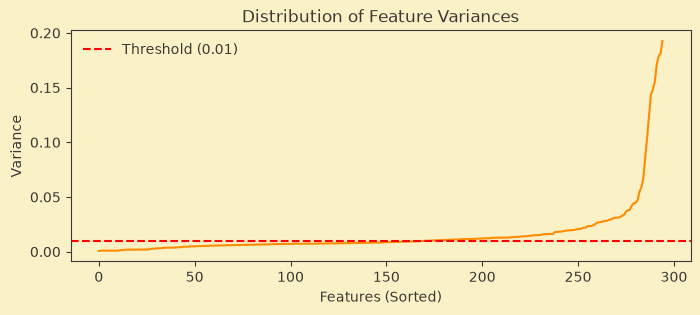

In [49]:
variances = X.var()
low_variance_threshold = 0.01
low_var_features = variances[variances < low_variance_threshold].index.tolist()
print(f"Found {len(low_var_features)} features with variance < {low_variance_threshold}.")

plt.figure(figsize=(8, 3))
plt.plot(sorted(variances.values), color='darkorange')
plt.axhline(y=low_variance_threshold, color='red', linestyle='--', label='Threshold (0.01)')
plt.title("Distribution of Feature Variances")
plt.ylabel("Variance")
plt.xlabel("Features (Sorted)")
plt.legend()
plt.show()

In [50]:
variances = X.var()
low_var_features = variances[variances < 0.01].index

# ANOVA test
important_low_var = []
for col in low_var_features:
    mask_0 = (X[col] == 0).values
    mask_1 = (X[col] != 0).values
    
    group_0 = y[mask_0]
    group_1 = y[mask_1]
    
    if len(group_1) > 2 and len(group_0) > 2: 
        f_stat, p_val = f_oneway(group_0, group_1)
        if p_val < 0.05:
            important_low_var.append(col)


print(f"Low variance features: {len(low_var_features)}")
print(f"Features with low varaince that have STRONG imapct on solubility (target): {len(important_low_var)}")


Low variance features: 172
Features with low varaince that have STRONG imapct on solubility (target): 43


In theory, low variance features could be subject to deletion. However, in cheminformatics, those values could mark very important characteristics of a compound. 
We performed ANOVA analysis to test which features are really important for solubility prediction. 

43 features are VERY important for solubility. They are rare, have low variance, but if they are present, they impact prediction. 

129 features don't show impact on solubility and theoretically could be dropped.

#### Checking how many features are highly correlated with the target
And how many of the low variance features are highly correlated with the target

Top 10% Correlation Threshold Value: 0.2252
Number of ANOVA features in the top 10% highest correlation: 8 (out of 43)



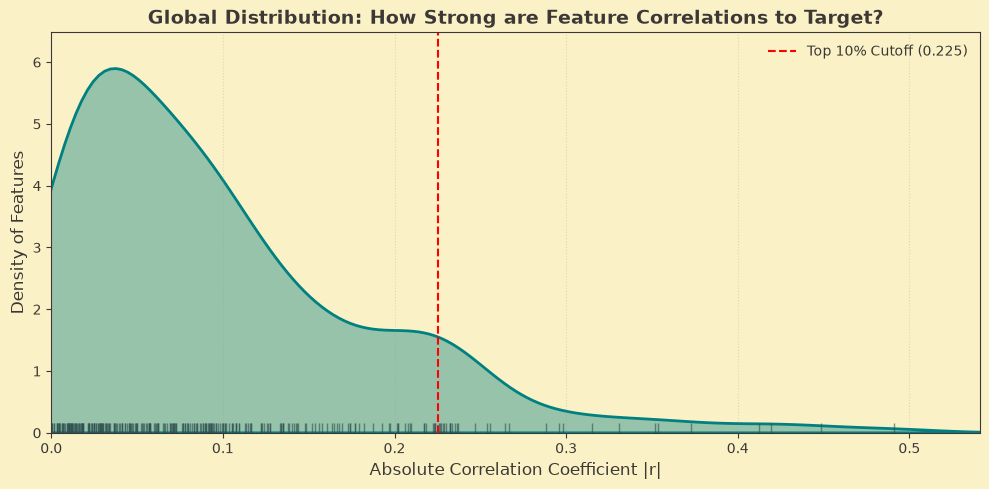

Correlation Strength Breakdown:
Strong Correlation (> 0.5):   0 features
Moderate Correlation (0.3-0.5): 9 features
Weak Correlation (< 0.3):     286 features


In [51]:
correlations = X.corrwith(y).abs()

top_10_percent_cutoff = correlations.quantile(0.90)
top_10_percent_features = correlations[correlations >= top_10_percent_cutoff].index

anova_in_top_10 = [col for col in important_low_var if col in top_10_percent_features]

print(f"Top 10% Correlation Threshold Value: {top_10_percent_cutoff:.4f}")
print(f"Number of ANOVA features in the top 10% highest correlation: {len(anova_in_top_10)} (out of {len(important_low_var)})\n")

fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(correlations, fill=True, color="teal", alpha=0.4, linewidth=2, ax=ax)
sns.rugplot(correlations, color="darkslategrey", alpha=0.6, ax=ax)

ax.axvline(top_10_percent_cutoff, color="red", linestyle="--", linewidth=1.5, 
           label=f"Top 10% Cutoff ({top_10_percent_cutoff:.3f})")
ax.set_title("Global Distribution: How Strong are Feature Correlations to Target?", fontsize=14, fontweight='bold')
ax.set_xlabel("Absolute Correlation Coefficient |r|", fontsize=12)
ax.set_ylabel("Density of Features", fontsize=12)
ax.set_xlim(0, correlations.max() + 0.05)
ax.grid(axis='x', alpha=0.3, linestyle=':')
ax.legend()

plt.tight_layout()
plt.show()

print("Correlation Strength Breakdown:")
print(f"Strong Correlation (> 0.5):   {sum(correlations > 0.5)} features")
print(f"Moderate Correlation (0.3-0.5): {sum((correlations >= 0.3) & (correlations <= 0.5))} features")
print(f"Weak Correlation (< 0.3):     {sum(correlations < 0.3)} features")


As we can see, we do not have a lot of strongly correlated features with respect to the target (solubility). That means that the solubility is based on complex function of the features rather than straighforward explanation of solubility with some feature. 

#### Futher check of correlation with the target

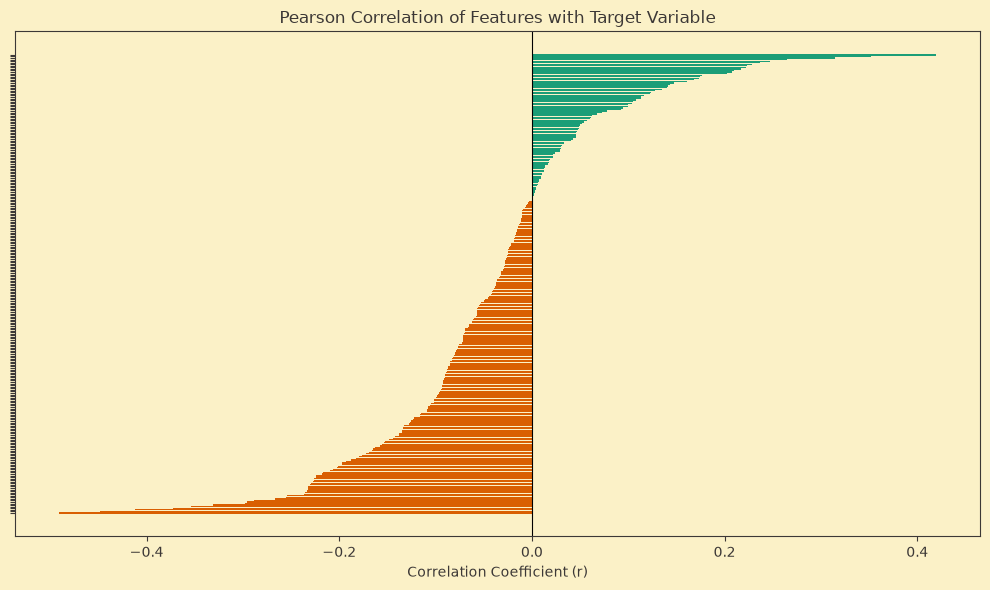

In [52]:
target_corr = X.corrwith(y).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#d95f02" if val < 0 else "#1b9e77" for val in target_corr.values]
bars = ax.barh(target_corr.index, target_corr.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
# ax.set_xlim(-1.0, 0.7)
ax.set_yticklabels("")
# ax.set_xticklabels("")
ax.set_title("Pearson Correlation of Features with Target Variable")
ax.set_xlabel("Correlation Coefficient (r)")
for bar in bars:
    w = bar.get_width()
    offset = 0.02 if w >= 0 else -0.08
plt.tight_layout()
plt.show()

The majority of the features have negative correlation, meaning that the higher the value, the lower the solubility. 
Majority of the features have weak correlation, meaning that they do not impact directly the solubility by themselves. As said before, it seems that solubility is complex function of the features.

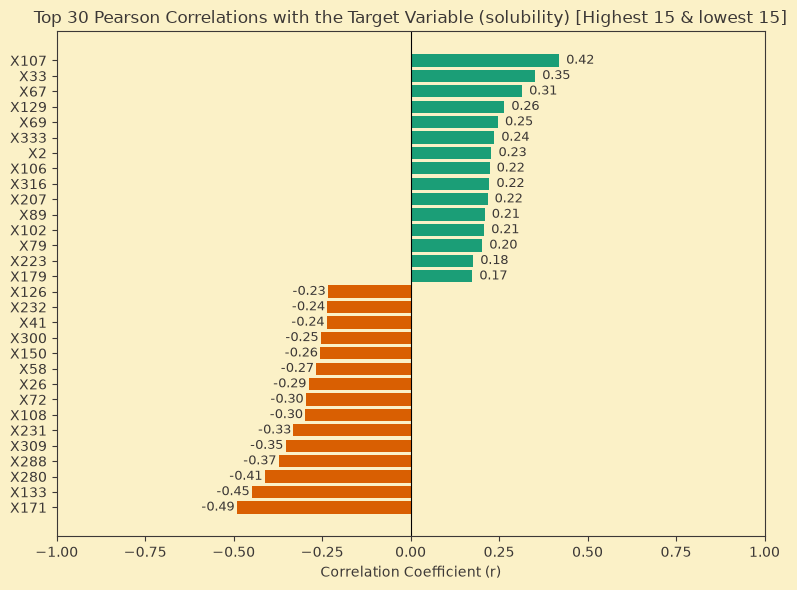

In [53]:
top_negative = target_corr.head(15)
top_positive = target_corr.tail(15)
filtered_corr = pd.concat([top_negative, top_positive])

fig, ax = plt.subplots(figsize=(8,6)) 
colors = ["#d95f02" if val < 0 else "#1b9e77" for val in filtered_corr.values]
bars = ax.barh(filtered_corr.index, filtered_corr.values, color=colors)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-1.0, 1.0)
ax.set_title("Top 30 Pearson Correlations with the Target Variable (solubility) [Highest 15 & lowest 15]")
ax.set_xlabel("Correlation Coefficient (r)")

for bar in bars:
    w = bar.get_width()
    offset = 0.02 if w >= 0 else -0.10
    ax.text(w + offset, bar.get_y() + bar.get_height() / 2, f"{w:.2f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

#### More in depth analysis of top correlating features:

Found 30 Top 10% features.


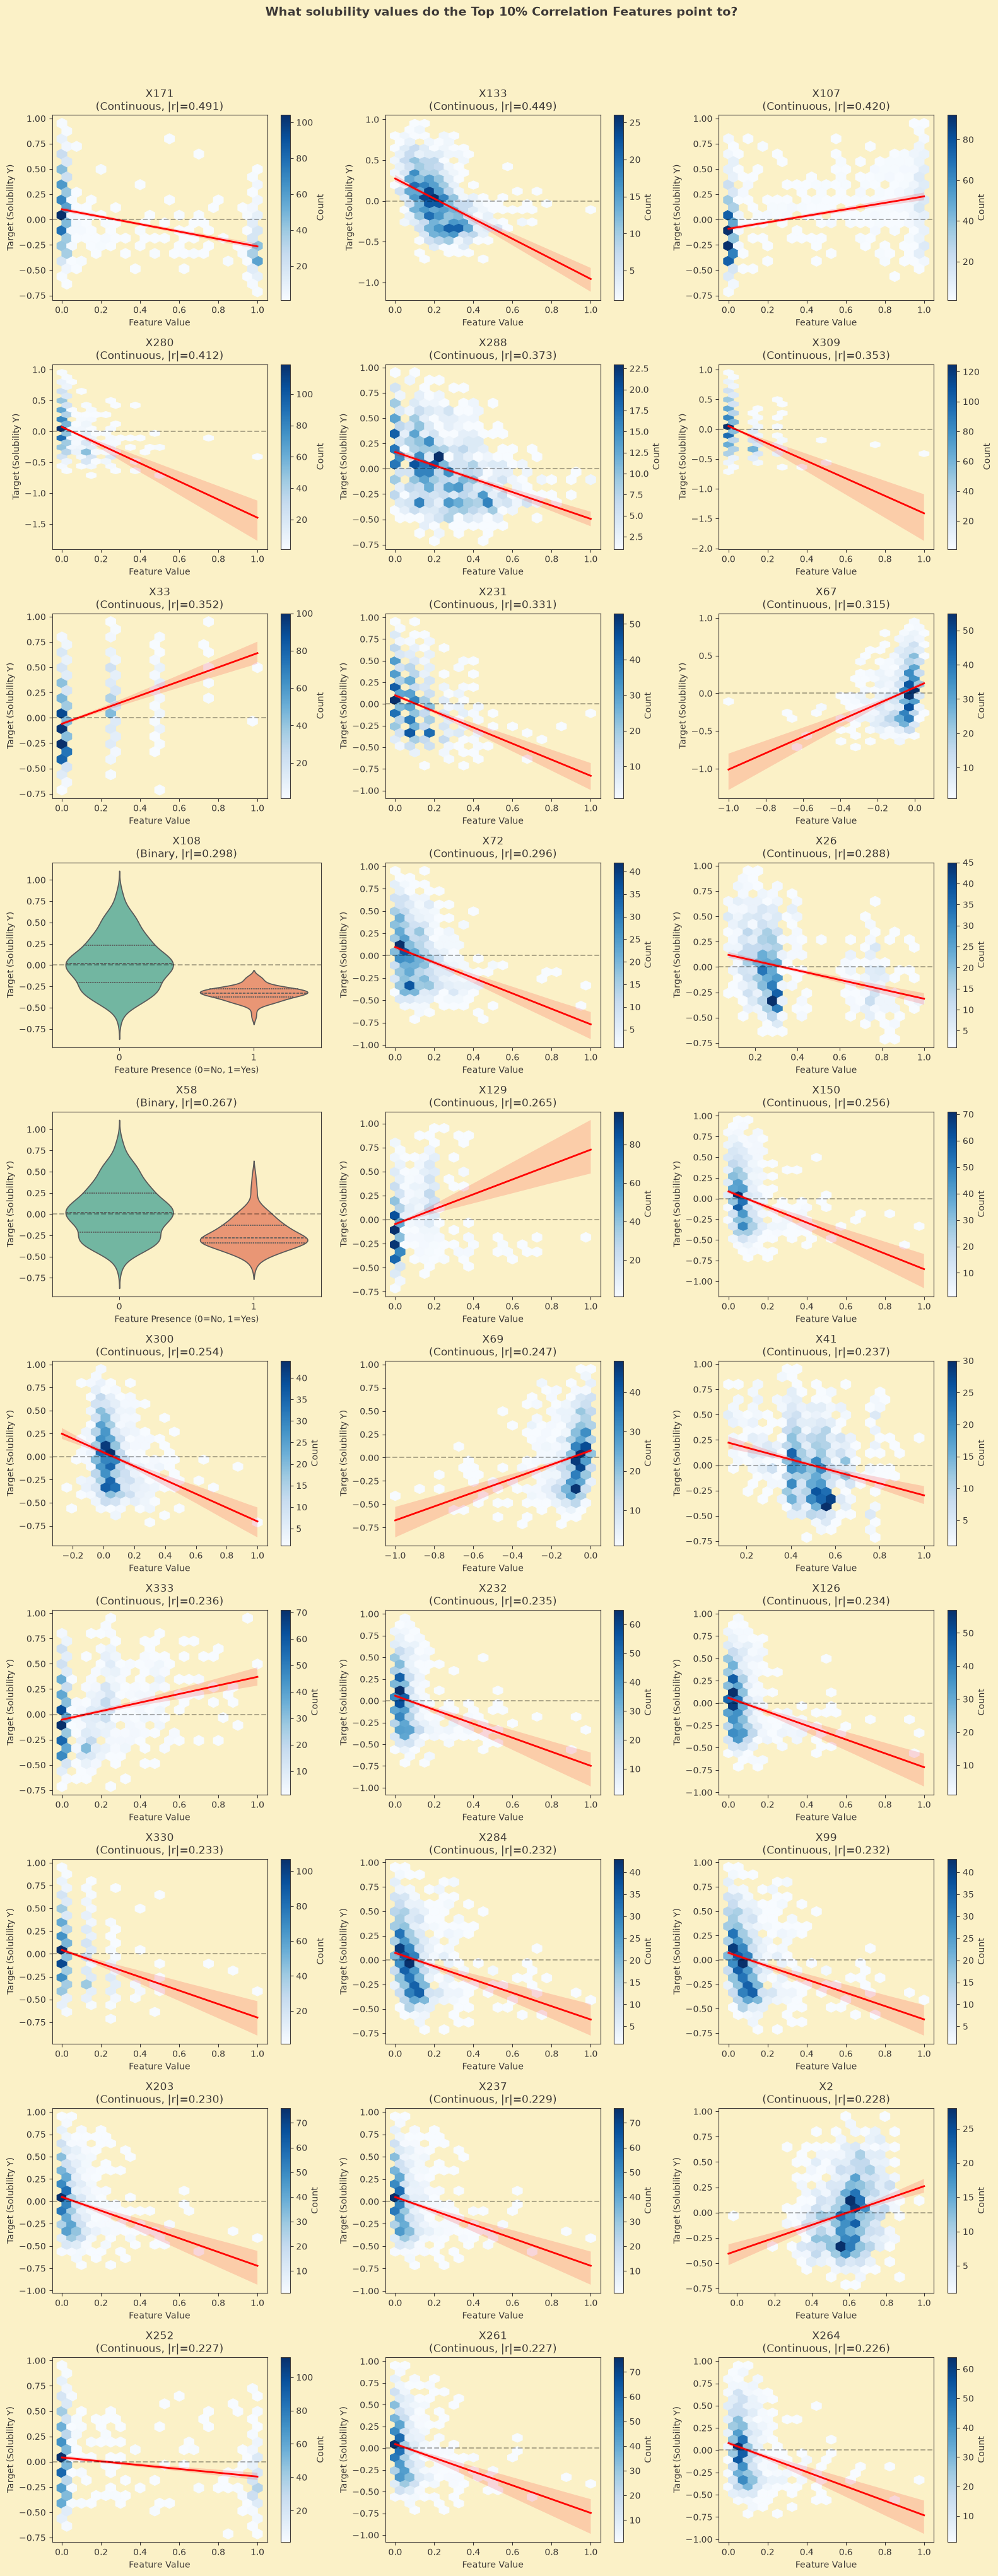

In [54]:
top_10_cols = top_10_percent_features.tolist()

print(f"Found {len(top_10_cols)} Top 10% features.")

def analyze_feature_target_mapping(feature_list, group_name, num_to_plot=30):
    sorted_features = correlations[feature_list].sort_values(ascending=False).index[:num_to_plot]
    
    fig, axes = plt.subplots(10, 3, figsize=(16,40))
    fig.suptitle(f"What solubility values do the {group_name} Features point to?", fontsize=14, fontweight='bold', y=1.02)
    axes = axes.flatten()
    
    for i, col in enumerate(sorted_features):
        ax = axes[i]
        
        is_binary = X[col].nunique() <= 2
        
        if is_binary:
            sns.violinplot(x=X[col], y=y, hue=X[col], ax=ax, palette="Set2", inner="quartile", legend=False)
            ax.set_title(f"{col}\n(Binary, |r|={correlations[col]:.3f})")
            ax.set_xlabel("Feature Presence (0=No, 1=Yes)")
        else:
            hb = ax.hexbin(X[col], y, gridsize=20, cmap="Blues", mincnt=1)
            fig.colorbar(hb, ax=ax, label='Count')
            sns.regplot(x=X[col], y=y, ax=ax, scatter=False, color="red", line_kws={"linewidth": 2})
            ax.set_title(f"{col}\n(Continuous, |r|={correlations[col]:.3f})")
            ax.set_xlabel("Feature Value")
            
        ax.set_ylabel("Target (Solubility Y)")
        ax.axhline(0, color='black', linestyle='--', alpha=0.3) # Reference line at Y=0

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

analyze_feature_target_mapping(top_10_cols, "Top 10% Correlation")

In [55]:
training_data['X33'].unique()

array([0.  , 0.75, 0.25, 0.5 , 1.  ])

As we can see the correlation directions are mixed. While all these features are in the top 10% for absolute correlation strength ($\vert{}r\vert{}$ ranging from 0.226 to 0.491), they affect the target (solubility) differently.

Features like X171, X133, X280, X288, X309, X231, X310, X20, X158, X302, X31, X173, X126, X226, X187, X88, X203, X112, X262, X241, and X264 have a negative correlation (red line slopes down, meaning higher feature values predict lower solubility).

On the other side, features X107, X33, X67, X120, X42, X111, and X2 have a positive correlation (higher values predict higher solubility).

The density hexbins show that for almost all these "top" continuous features, the vast majority of molecules have a feature value at or very near 0.0.

Because most data is clustered near zero, the strong correlation slopes are largely driven by a smaller subset of molecules that actually possess higher values for these features. When these rare higher values occur, they drastically shift the predicted solubility.

We can also observe 'bands' of values in some of the features. That would mean that the values are not continous, but have some specific values eg.for X33 we have array([0.  , 0.75, 0.25, 0.5 , 1.  ]). This may be a reason to differently treat those values in preprocessing. This banding is also very distinct in X20, X226, and X203.

For X171 we can clearly see that higher values correspond to worse solubility. The same can be deducted in X133, X282, X231, X310, X158, X302, X173, X126, X187, X88, X112, and X241 just by looking at the hexbins. Hhigher feature values hexbins are below the group of the hexbins that are around 0.0 solubility for most.

There are also two binary features, X108 and X58, represented by violin plots. For both of these features, the vast majority of molecules have a value of 0, which is centered near a solubility of 0.0. The much smaller group of molecules where the feature is present (Feature Presence = True, value of 1) has a noticeably lower median solubility, indicating a negative relationship with the target.

## Understanding correlation between features

We first wanted to show just the top correlating features, but discovered a very interesting pattern. Hence, we print out the correlation for all the features. 

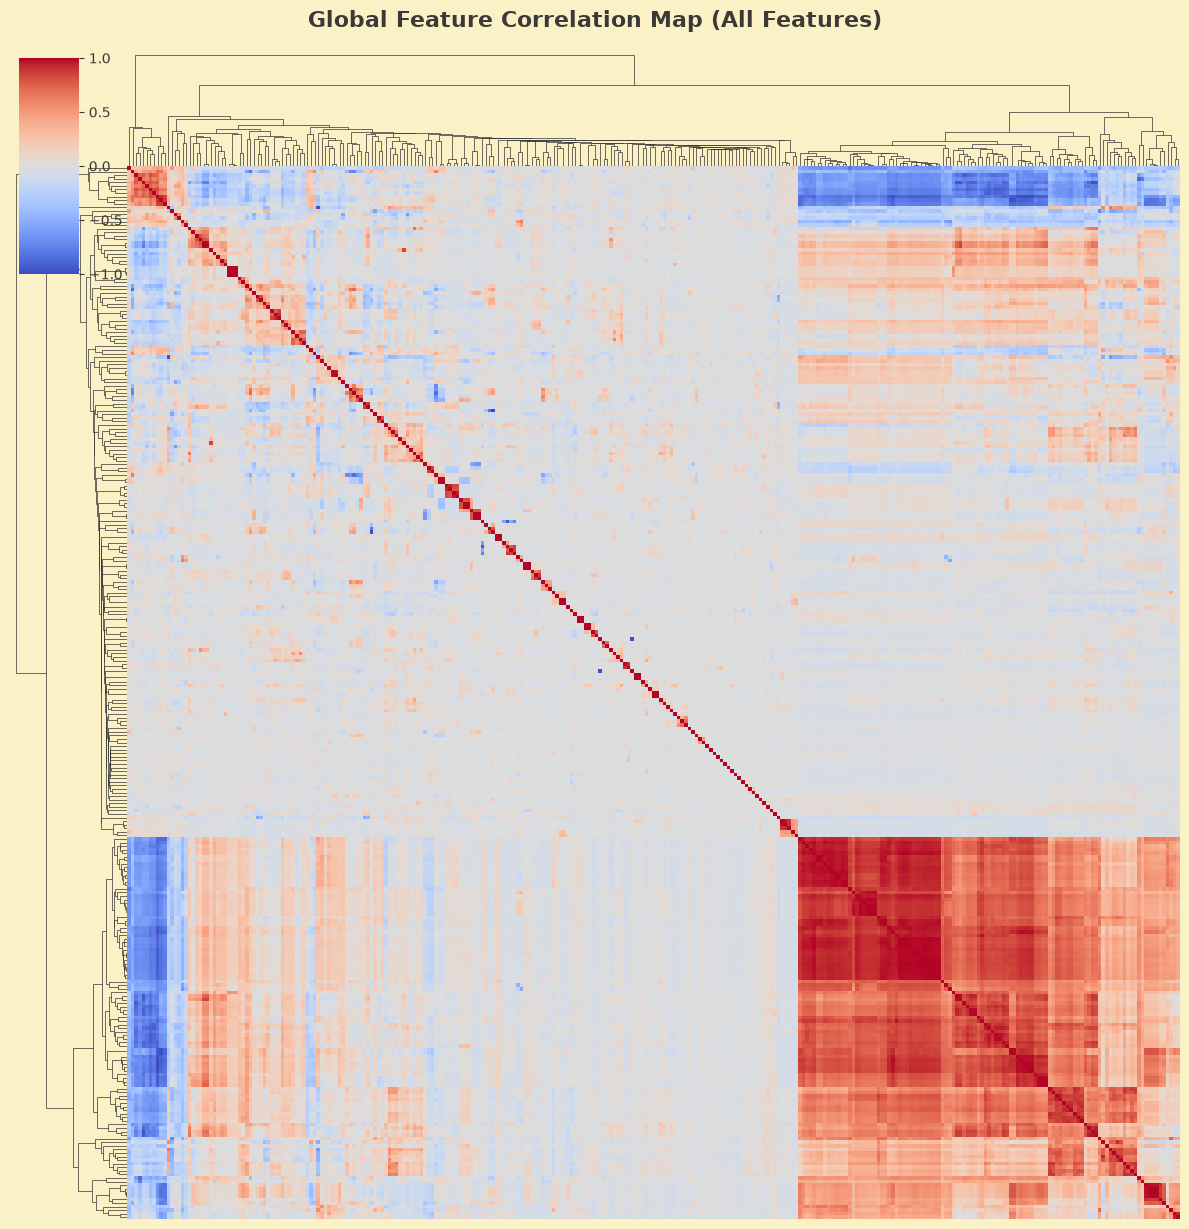

In [56]:
full_corr = X.corr()

g = sns.clustermap(full_corr, 
                   cmap="coolwarm", 
                   vmin=-1, vmax=1,
                   annot=False,        
                   xticklabels=False,  
                   yticklabels=False,  
                   figsize=(12, 12),
                   dendrogram_ratio=0.1)

g.fig.suptitle("Global Feature Correlation Map (All Features)", fontsize=16, fontweight='bold', y=1.02)
plt.show()

We can see a very interesing block of features that have strong correlation with each other. This indicates that a lot of featues are redundant, as one indicates the change in another. 

We can also see that the features that are in the red block have also a strong negative coorelation with other features. 

This may finally indicate that some kind of feature engeineering may be an optimal approach.

The dendrogram divides the features into 2 main clusters: the highly correlated ones and the grey area that does not have high correlation. Those are far more complex features. 

#### How do there high correlation feature pairs look in comparison with the features correlating with target variable?

In [57]:
HIGH_CORR_THRESHOLD = 0.80

corr_matrix = full_corr.abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# 2. Stack and filter for high correlations
stacked_corr = upper_tri.stack().reset_index()
stacked_corr.columns = ['Feature_1', 'Feature_2', 'Correlation']
high_corr_pairs = stacked_corr[stacked_corr['Correlation'] >= HIGH_CORR_THRESHOLD]

# 3. Combine both feature columns, filter for target features, and count occurrences
all_features_in_pairs = pd.concat([high_corr_pairs['Feature_1'], high_corr_pairs['Feature_2']])
target_counts = all_features_in_pairs[all_features_in_pairs.isin(top_10_cols)].value_counts()

# 4. Print results
print(f"Top 10% features that have high correlation with target variable in high-correlation \nfeatures pairs (|r| >= {HIGH_CORR_THRESHOLD}):")
if target_counts.empty:
    print("None of the target features appear in highly correlated pairs.")
else:
    for feature, count in target_counts.items():
        print(f"{feature}: {count} pair(s)")

Top 10% features that have high correlation with target variable in high-correlation 
features pairs (|r| >= 0.8):
X264: 50 pair(s)
X150: 45 pair(s)
X99: 30 pair(s)
X284: 30 pair(s)
X232: 28 pair(s)
X69: 27 pair(s)
X126: 18 pair(s)
X261: 6 pair(s)
X203: 5 pair(s)
X237: 5 pair(s)
X72: 4 pair(s)
X33: 1 pair(s)
X67: 1 pair(s)
X107: 1 pair(s)
X171: 1 pair(s)
X333: 1 pair(s)
X300: 1 pair(s)
X129: 1 pair(s)
X280: 1 pair(s)


This shows us that we can have a problem with the diluted feature importance. When using a tree boosting model it will randomly pick between X264 and its 50 highly correlated twins. This dilutes feature importance, making it look like 50 features are "weakly important" instead of recognizing that 1 feature is highly important. 

## Dimensionality reduction visualisation

In [58]:
tsne_3d = TSNE(n_components=3, perplexity=30, random_state=42, init='pca', learning_rate='auto')
X_tsne_3d = tsne_3d.fit_transform(X_scaled)

fig = px.scatter_3d(
    x=X_tsne_3d[:, 0], 
    y=X_tsne_3d[:, 1], 
    z=X_tsne_3d[:, 2],
    color=y,
    color_continuous_scale='icefire', 
    title="3D t-SNE Projection of Chemical Features",
    labels={'color': 'Solubility Target'},
    width=1000,   
    height=600    
)

fig.update_traces(marker=dict(size=4, opacity=0.7, line=dict(width=0.5, color='DarkSlateGrey')))
camera_zoom = dict(
    eye=dict(x=0.8, y=0.8, z=0.8) 
)
fig.update_layout(scene_camera=camera_zoom)
fig.show()

In [59]:
umap_3d = umap.UMAP(n_components=3, n_neighbors=15, min_dist=0.1, random_state=42)
X_umap_3d = umap_3d.fit_transform(X_scaled)

fig = px.scatter_3d(
    x=X_umap_3d[:, 0], 
    y=X_umap_3d[:, 1], 
    z=X_umap_3d[:, 2],
    color=y,
    color_continuous_scale='icefire', 
    title="3D UMAP Projection of Chemical Features",
    labels={'color': 'Solubility Target'},
    width=1000,   
    height=600   
)

fig.update_traces(marker=dict(size=4, opacity=0.7, line=dict(width=0.5, color='DarkSlateGrey')))
camera_zoom = dict(
    eye=dict(x=0.8, y=0.8, z=0.8) 
)
fig.update_layout(scene_camera=camera_zoom)
fig.show()

C:\Users\mary9\AppData\Local\Programs\Python\Python314\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Both t-SNE and UMAP show that the data is not separating into isolated, clearly separable islands. It is a continous manifold with local groupings of low or high solubility.

While compounds generally display smooth solubility gradient, we can see that tight clusters have sudden color transition. This confirms ANOVA finding that the rare binary groups act as activity switch. 

# Model

In [2]:
from dataclasses import asdict, dataclass
from typing import NamedTuple
 
import lightgbm as lgb
import numpy as np
import optuna
import pandas as pd
import wandb
import xgboost as xgb
from catboost import CatBoostRegressor
from scipy.stats import f_oneway
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest, StackingRegressor, VotingRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
 
DATA_PATH = "../../challenge/TrainingData_Blinded.csv"
WANDB_PROJECT = "solubility-challenge"
SEED = 42
DRIVERS = {"X107", "X171", "X133", "X33", "X280"}

## Data loading, outlier removal, split

In [3]:
class Split(NamedTuple):
    X_train: pd.DataFrame
    X_val: pd.DataFrame
    X_test: pd.DataFrame
    y_train: pd.Series
    y_val: pd.Series
    y_test: pd.Series
 
 
def load_data(path=DATA_PATH):
    df = pd.read_csv(path, index_col="Name").rename(columns={"Y": "target"})
    return df.drop(columns="target"), df["target"]
 
 
def remove_outliers(X, y, contamination=0.05, mahalanobis_percentile=95, pca_variance=0.90):
    iso_outliers = IsolationForest(contamination=contamination, random_state=SEED).fit_predict(X) == -1
 
    pca = PCA(n_components=pca_variance, random_state=SEED)
    components = pca.fit_transform(StandardScaler().fit_transform(X))
    mahalanobis_sq = np.sum(components ** 2 / pca.explained_variance_, axis=1)
    pca_outliers = mahalanobis_sq > np.percentile(mahalanobis_sq, mahalanobis_percentile)
 
    keep = ~(iso_outliers & pca_outliers)
    return X.loc[keep].copy(), y.loc[keep].copy()
 
 
def make_split(X, y, val_size=0.1, test_size=0.1, n_bins=5):
    bins = pd.qcut(y, q=n_bins, labels=False, duplicates="drop")
    holdout = val_size + test_size
    X_train, X_hold, y_train, y_hold, _, bins_hold = train_test_split(
        X, y, bins, test_size=holdout, stratify=bins, random_state=SEED
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_hold, y_hold, test_size=test_size / holdout, stratify=bins_hold, random_state=SEED
    )
    return Split(X_train, X_val, X_test, y_train, y_val, y_test)
 
 
_SPLITS = {}
 
 
def get_split(outliers=True):
    if outliers not in _SPLITS:
        X, y = load_data()
        if outliers:
            X, y = remove_outliers(X, y)
        _SPLITS[outliers] = make_split(X, y)
    return _SPLITS[outliers]

## Preprocessing transformers

In [4]:
class ChemistryFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, prune=True, engineer=True, var_threshold=0.01, alpha=0.05, top_k=30):
        self.prune = prune
        self.engineer = engineer
        self.var_threshold = var_threshold
        self.alpha = alpha
        self.top_k = top_k
 
    def fit(self, X, y):
        X = pd.DataFrame(X)
        y = np.asarray(y)
        variances = X.var()
        low_var = variances[variances < self.var_threshold].index.tolist()
 
        self.important_ = []
        for col in low_var:
            zero = (X[col] == 0).to_numpy()
            if zero.sum() > 2 and (~zero).sum() > 2:
                _, p_value = f_oneway(y[zero], y[~zero])
                if p_value < self.alpha:
                    self.important_.append(col)
 
        self.dead_ = [c for c in low_var if c not in self.important_] if self.prune else []
        kept = X.drop(columns=self.dead_)
        self.binary_cols_ = [c for c in kept.columns if kept[c].nunique() <= 2]
        correlations = kept.corrwith(pd.Series(y, index=kept.index)).abs()
        self.top_cols_ = correlations.nlargest(self.top_k).index.tolist()
        return self
 
    def transform(self, X):
        d = pd.DataFrame(X).drop(columns=self.dead_).copy()
        if not self.engineer:
            return d
        d["active_binary_sum"] = d[self.binary_cols_].sum(axis=1)
        d["active_anova_count"] = (d[self.important_] != 0).sum(axis=1)
        d["active_top_count"] = (d[self.top_cols_] != 0).sum(axis=1)
        if DRIVERS.issubset(d.columns):
            d["inter_X107_minus_X171"] = d["X107"] - d["X171"]
            d["inter_X107_prod_X171"] = d["X107"] * d["X171"]
            d["inter_X33_minus_X133"] = d["X33"] - d["X133"]
            d["inter_pos_sum"] = d["X107"] + d["X33"]
            d["inter_neg_sum"] = d["X171"] + d["X133"] + d["X280"]
            d["inter_net_driver"] = d["inter_pos_sum"] - d["inter_neg_sum"]
        return d
 
 
class CorrelationFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.80, mode="drop", pca_variance=0.95):
        self.threshold = threshold
        self.mode = mode
        self.pca_variance = pca_variance
 
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        corr = X.corr().abs()
        upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        self.correlated_ = [c for c in upper.columns if (upper[c] >= self.threshold).any()]
        self.independent_ = [c for c in X.columns if c not in self.correlated_]
        if self.mode == "pca" and self.correlated_:
            self.pca_ = Pipeline([
                ("scaler", StandardScaler()),
                ("pca", PCA(n_components=self.pca_variance, random_state=SEED)),
            ]).fit(X[self.correlated_])
        return self
 
    def transform(self, X):
        X = pd.DataFrame(X)
        base = X[self.independent_].copy()
        if self.mode == "drop" or not self.correlated_:
            return base
        components = self.pca_.transform(X[self.correlated_])
        pcs = pd.DataFrame(
            components, index=X.index, columns=[f"pca_{i}" for i in range(components.shape[1])]
        )
        return pd.concat([base, pcs], axis=1)
 
 
PREPROCESSING = {
    "none": lambda: [],
    "drop_correlated": lambda: [("corr", CorrelationFilter(mode="drop"))],
    "selective_pca": lambda: [("corr", CorrelationFilter(mode="pca"))],
    "pca": lambda: [("scaler", StandardScaler()), ("pca", PCA(n_components=0.95, random_state=SEED))],
    "chem": lambda: [("chem", ChemistryFeatures())],
    "chem_drop_correlated": lambda: [
        ("chem", ChemistryFeatures()),
        ("corr", CorrelationFilter(mode="drop")),
    ],
    "chem_selective_pca": lambda: [
        ("chem", ChemistryFeatures()),
        ("corr", CorrelationFilter(mode="pca")),
    ],
}

##  Models, parameter sets, ensembles

In [5]:
MODEL_REGISTRY = {
    "xgb": (xgb.XGBRegressor, {"random_state": SEED, "objective": "reg:squarederror"}),
    "lgb": (lgb.LGBMRegressor, {"random_state": SEED, "verbose": -1}),
    "cat": (CatBoostRegressor, {"random_state": SEED, "verbose": False}),
    "xgb_huber": (xgb.XGBRegressor, {"random_state": SEED, "objective": "reg:pseudohubererror"}),
    "lgb_huber": (lgb.LGBMRegressor, {"random_state": SEED, "objective": "huber", "verbose": -1}),
}
 
PARAM_SETS = {
    "default": {},
    "tuned": {
        "xgb": {
            "colsample_bytree": 0.6711639086989265,
            "gamma": 0.009690823994704606,
            "learning_rate": 0.008322155579602922,
            "max_depth": 10,
            "min_child_weight": 12,
            "n_estimators": 800,
        },
        "lgb": {
            "colsample_bytree": 0.6441655087757244,
            "learning_rate": 0.03334803553575572,
            "max_depth": 9,
            "n_estimators": 800,
            "num_leaves": 247,
            "reg_alpha": 1.5480238030447174e-05,
            "reg_lambda": 2.1015086746836687e-06,
            "subsample": 0.6386093564031781,
        },
        "cat": {
            "depth": 5,
            "iterations": 800,
            "l2_leaf_reg": 0.07632925023190759,
            "learning_rate": 0.022493454629956968,
            "random_strength": 0.38383631752285124,
            "subsample": 0.7702678281844455,
            "bootstrap_type": "Bernoulli",
        },
    },
}
 
ENSEMBLES = ("single", "average", "stack_ridge", "stack_positive")
 
 
def resolved_params(name, param_set):
    _, base = MODEL_REGISTRY[name]
    family = name.split("_")[0]
    overrides = PARAM_SETS[param_set].get(name, PARAM_SETS[param_set].get(family, {}))
    return {**base, **overrides}
 
 
def make_model(name, param_set="default"):
    cls, _ = MODEL_REGISTRY[name]
    return cls(**resolved_params(name, param_set))
 
 
def build_estimator(models, param_set, ensemble):
    estimators = [(name, make_model(name, param_set)) for name in models]
    if ensemble == "single":
        if len(estimators) != 1:
            raise ValueError("ensemble='single' needs exactly one model")
        return estimators[0][1]
    if ensemble == "average":
        return VotingRegressor(estimators, n_jobs=-1)
    final = RidgeCV() if ensemble == "stack_ridge" else LinearRegression(positive=True)
    return StackingRegressor(
        estimators,
        final_estimator=final,
        cv=KFold(n_splits=5, shuffle=True, random_state=SEED),
        n_jobs=-1,
    )

## Experiment runner with wandb tracking

In [6]:
@dataclass
class RunConfig:
    name: str = ""
    preprocessing: str = "none"
    models: tuple = ("cat",)
    ensemble: str = "single"
    params: str = "default"
    outliers: bool = True
    cv: bool = False
    group: str = ""
 
    def __post_init__(self):
        if not self.name:
            data = "clean" if self.outliers else "raw"
            self.name = f"{self.preprocessing}|{'+'.join(self.models)}|{self.ensemble}|{self.params}|{data}"
 
 
def run_experiment(cfg, project=WANDB_PROJECT):
    split = get_split(cfg.outliers)
    steps = PREPROCESSING[cfg.preprocessing]()
    pipeline = Pipeline(steps + [("model", build_estimator(cfg.models, cfg.params, cfg.ensemble))])
 
    run = wandb.init(
        project=project,
        name=cfg.name,
        group=cfg.group or None,
        tags=[cfg.preprocessing, cfg.ensemble, cfg.params, *cfg.models],
        config={
            **asdict(cfg),
            "model_params": {m: resolved_params(m, cfg.params) for m in cfg.models},
            "n_train": len(split.y_train),
            "n_val": len(split.y_val),
            "n_test": len(split.y_test),
        },
        reinit=True,
    )
 
    pipeline.fit(split.X_train, split.y_train)
 
    metrics = {}
    for part in ("train", "val", "test"):
        X_part, y_part = getattr(split, f"X_{part}"), getattr(split, f"y_{part}")
        metrics[f"{part}_rmse"] = root_mean_squared_error(y_part, pipeline.predict(X_part))
 
    if cfg.cv:
        scores = cross_val_score(
            clone(pipeline),
            split.X_train,
            split.y_train,
            cv=KFold(n_splits=5, shuffle=True, random_state=SEED),
            scoring="neg_root_mean_squared_error",
            n_jobs=-1,
        )
        metrics["cv_rmse"] = -scores.mean()
        metrics["cv_rmse_std"] = scores.std()
 
    metrics["n_features"] = (
        pipeline[:-1].transform(split.X_train).shape[1] if steps else split.X_train.shape[1]
    )
 
    if cfg.ensemble.startswith("stack"):
        coefs = pipeline.named_steps["model"].final_estimator_.coef_
        for name, weight in zip(cfg.models, coefs):
            metrics[f"weight_{name}"] = float(weight)
 
    wandb.log(metrics)
    run.summary.update(metrics)
    run.finish()
 
    return {
        "name": cfg.name,
        "preprocessing": cfg.preprocessing,
        "models": "+".join(cfg.models),
        "ensemble": cfg.ensemble,
        "params": cfg.params,
        "outliers": cfg.outliers,
        **metrics,
    }
 
 
def run_all(configs):
    rows = [run_experiment(cfg) for cfg in configs]
    return pd.DataFrame(rows).sort_values("val_rmse").reset_index(drop=True)
 

## Hyperparameter tuning (separate from the pipeline), run  before refactoring ,   saved    here    for history

In [7]:
FIXED_TUNING_PARAMS = {"cat": {"bootstrap_type": "Bernoulli"}}
 
 
def suggest_params(trial, family):
    if family == "xgb":
        return {
            "n_estimators": trial.suggest_int("n_estimators", 200, 1500),
            "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
            "max_depth": trial.suggest_int("max_depth", 3, 10),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 15),
            "gamma": trial.suggest_float("gamma", 1e-8, 1.0, log=True),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        }
    if family == "lgb":
        return {
            "n_estimators": trial.suggest_int("n_estimators", 200, 1500),
            "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
            "max_depth": trial.suggest_int("max_depth", 3, 10),
            "num_leaves": trial.suggest_int("num_leaves", 15, 255),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0),
            "subsample_freq": 1,
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "min_child_samples": trial.suggest_int("min_child_samples", 5, 50),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        }
    if family == "cat":
        return {
            "iterations": trial.suggest_int("iterations", 200, 1500),
            "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
            "depth": trial.suggest_int("depth", 3, 10),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0),
            "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1e-2, 10.0, log=True),
            "random_strength": trial.suggest_float("random_strength", 1e-8, 10.0, log=True),
        }
    raise ValueError(family)
 
 
def tune(model_name, preprocessing="none", outliers=True, n_trials=50):
    split = get_split(outliers)
    family = model_name.split("_")[0]
    fixed = FIXED_TUNING_PARAMS.get(family, {})
    cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
    cls, base = MODEL_REGISTRY[model_name]
 
    def objective(trial):
        model = cls(**{**base, **fixed, **suggest_params(trial, family)})
        pipeline = Pipeline(PREPROCESSING[preprocessing]() + [("model", model)])
        scores = cross_val_score(
            pipeline, split.X_train, split.y_train,
            cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
        )
        return -scores.mean()
 
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials)
    print(f"[{model_name}] best CV RMSE: {study.best_value:.4f}")
    return {**fixed, **study.best_params}
 

In [6]:
wandb.login()

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from WANDB_API_KEY.
wandb: Currently logged in as: bialkass (KnowledgeExtraction) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


True

#  All runs logged in wandb (at the end there is a photo with results from wandb)

## Run 1: baseline (CatBoost defaults on outlier-cleaned data)

In [ ]:
baseline = run_all([RunConfig(name="baseline_cat_default", models=("cat",), cv=True, group="baseline")])
baseline

wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


cv_rmse,▁
cv_rmse_std,▁
n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
cv_rmse,0.21678
cv_rmse_std,0.00813
n_features,295
test_rmse,0.22158
train_rmse,0.03655


,name,preprocessing,models,ensemble,params,outliers,train_rmse,val_rmse,test_rmse,cv_rmse,cv_rmse_std,n_features
0,baseline_cat_default,none,cat,single,default,True,0.036554,0.184367,0.221576,0.216776,0.008127,295


Run 2: preprocessing x model comparison with default parameters

In [8]:
configs = [
    RunConfig(preprocessing=prep, models=(model,), group="preprocessing_vs_model")
    for prep in PREPROCESSING
    for model in MODEL_REGISTRY
]
configs.append(RunConfig(preprocessing="none", models=("cat",), outliers=False, group="preprocessing_vs_model"))
preprocessing_results = run_all(configs)
preprocessing_results

n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
n_features,295
test_rmse,0.23041
train_rmse,0.0016
val_rmse,0.22514


n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
n_features,295
test_rmse,0.23936
train_rmse,0.03311
val_rmse,0.19739


n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
n_features,295
test_rmse,0.22158
train_rmse,0.03655
val_rmse,0.18437


n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
n_features,295
test_rmse,0.23085
train_rmse,0.00144
val_rmse,0.22545


n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
n_features,295
test_rmse,0.23662
train_rmse,0.03323
val_rmse,0.19672


n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
n_features,158
test_rmse,0.25302
train_rmse,0.00373
val_rmse,0.22479


... (28 outputs left out)

n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
n_features,126
test_rmse,0.25588
train_rmse,0.00172
val_rmse,0.21802


n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
n_features,126
test_rmse,0.22515
train_rmse,0.03526
val_rmse,0.20187


n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
n_features,295
test_rmse,0.21692
train_rmse,0.03566
val_rmse,0.18962


,name,preprocessing,models,ensemble,params,outliers,train_rmse,val_rmse,test_rmse,n_features
0,none|cat|single|default|clean,none,cat,single,default,True,0.036554,0.184367,0.221576,295
1,selective_pca|cat|single|default|clean,selective_pca,cat,single,default,True,0.032522,0.187121,0.233607,189
2,none|cat|single|default|raw,none,cat,single,default,False,0.035663,0.189623,0.216924,295
3,chem|cat|single|default|clean,chem,cat,single,default,True,0.042683,0.190741,0.229689,158
4,chem_selective_pca|cat|single|default|clean,chem_selective_pca,cat,single,default,True,0.040403,0.192679,0.230774,126
5,drop_correlated|cat|single|default|clean,drop_correlated,cat,single,default,True,0.043916,0.192708,0.234022,158
6,none|lgb_huber|single|default|clean,none,lgb_huber,single,default,True,0.033227,0.196724,0.236619,295
7,none|lgb|single|default|clean,none,lgb,single,default,True,0.033111,0.197395,0.239359,295
8,chem_drop_correlated|cat|single|default|clean,chem_drop_correlated,cat,single,default,True,0.047480,0.199122,0.231107,105
9,chem|lgb_huber|single|default|clean,chem,lgb_huber,single,default,True,0.040080,0.199903,0.236158,158


Run 3: tuned single models

In [9]:
configs = [
    RunConfig(preprocessing="none", models=(model,), params="tuned", cv=True, group="tuned_singles")
    for model in ("xgb", "lgb", "cat")
]
tuned_results = run_all(configs)
tuned_results

cv_rmse,▁
cv_rmse_std,▁
n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
cv_rmse,0.22482
cv_rmse_std,0.00849
n_features,295
test_rmse,0.22996
train_rmse,0.05172


cv_rmse,▁
cv_rmse_std,▁
n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
cv_rmse,0.22053
cv_rmse_std,0.0077
n_features,295
test_rmse,0.22636
train_rmse,0.01425


cv_rmse,▁
cv_rmse_std,▁
n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
cv_rmse,0.21665
cv_rmse_std,0.01049
n_features,295
test_rmse,0.2282
train_rmse,0.0787


,name,preprocessing,models,ensemble,params,outliers,train_rmse,val_rmse,test_rmse,cv_rmse,cv_rmse_std,n_features
0,none|cat|single|tuned|clean,none,cat,single,tuned,True,0.078698,0.184424,0.228202,0.216645,0.010491,295
1,none|lgb|single|tuned|clean,none,lgb,single,tuned,True,0.014245,0.191571,0.226358,0.220529,0.007705,295
2,none|xgb|single|tuned|clean,none,xgb,single,tuned,True,0.051719,0.195590,0.229958,0.224825,0.008493,295


Run 4: ensembles

In [10]:
ensemble_models = ("xgb", "lgb", "cat")
configs = [
    RunConfig(preprocessing=prep, models=ensemble_models, ensemble=ens, params=params, group="ensembles")
    for prep in ("none", "chem", "chem_selective_pca")
    for ens in ("average", "stack_ridge", "stack_positive")
    for params in ("default", "tuned")
]
ensemble_results = run_all(configs)
ensemble_results

n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
n_features,295
test_rmse,0.22402
train_rmse,0.02153
val_rmse,0.19588


n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
n_features,295
test_rmse,0.22453
train_rmse,0.04591
val_rmse,0.18823


n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
weight_cat,▁
weight_lgb,▁
weight_xgb,▁
n_features,295
test_rmse,0.22495
train_rmse,0.03713
val_rmse,0.18256


n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
weight_cat,▁
weight_lgb,▁
weight_xgb,▁
n_features,295
test_rmse,0.22669
train_rmse,0.05351
val_rmse,0.18444


n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
weight_cat,▁
weight_lgb,▁
weight_xgb,▁
n_features,295
test_rmse,0.22251
train_rmse,0.03271
val_rmse,0.18442


n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
weight_cat,▁
weight_lgb,▁
weight_xgb,▁
n_features,295
test_rmse,0.2262
train_rmse,0.05647
val_rmse,0.18488


... (10 outputs left out)

n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
weight_cat,▁
weight_lgb,▁
weight_xgb,▁
n_features,126
test_rmse,0.23042
train_rmse,0.05628
val_rmse,0.19931


n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
weight_cat,▁
weight_lgb,▁
weight_xgb,▁
n_features,126
test_rmse,0.22887
train_rmse,0.03682
val_rmse,0.19276


n_features,▁
test_rmse,▁
train_rmse,▁
val_rmse,▁
weight_cat,▁
weight_lgb,▁
weight_xgb,▁
n_features,126
test_rmse,0.23049
train_rmse,0.06172
val_rmse,0.19948


,name,preprocessing,models,ensemble,params,outliers,train_rmse,val_rmse,test_rmse,n_features,weight_xgb,weight_lgb,weight_cat
0,none|xgb+lgb+cat|stack_ridge|default|clean,none,xgb+lgb+cat,stack_ridge,default,True,0.037126,0.182555,0.224951,295,-0.139488,0.197636,0.956704
1,none|xgb+lgb+cat|stack_positive|default|clean,none,xgb+lgb+cat,stack_positive,default,True,0.032707,0.184424,0.222512,295,0.000000,0.112124,0.908631
2,none|xgb+lgb+cat|stack_ridge|tuned|clean,none,xgb+lgb+cat,stack_ridge,tuned,True,0.053510,0.184435,0.226692,295,-0.230360,0.453294,0.796693
3,none|xgb+lgb+cat|stack_positive|tuned|clean,none,xgb+lgb+cat,stack_positive,tuned,True,0.056471,0.184878,0.226204,295,0.000000,0.282521,0.745826
4,chem|xgb+lgb+cat|stack_positive|tuned|clean,chem,xgb+lgb+cat,stack_positive,tuned,True,0.080885,0.187479,0.222364,158,0.000000,0.004559,1.003714
5,chem|xgb+lgb+cat|stack_ridge|tuned|clean,chem,xgb+lgb+cat,stack_ridge,tuned,True,0.079120,0.187762,0.222301,158,-0.032154,0.050977,0.985691
6,none|xgb+lgb+cat|average|tuned|clean,none,xgb+lgb+cat,average,tuned,True,0.045906,0.188227,0.224535,295,NaN,NaN,NaN
7,chem|xgb+lgb+cat|stack_positive|default|clean,chem,xgb+lgb+cat,stack_positive,default,True,0.038735,0.191361,0.227912,158,0.129787,0.013596,0.845012
8,chem|xgb+lgb+cat|stack_ridge|default|clean,chem,xgb+lgb+cat,stack_ridge,default,True,0.038532,0.191435,0.227766,158,0.134009,0.025531,0.827781
9,chem_selective_pca|xgb+lgb+cat|stack_positive|...,chem_selective_pca,xgb+lgb+cat,stack_positive,default,True,0.036821,0.192764,0.228871,126,0.000000,0.240137,0.761390


In [ ]:
# PARAM_SETS["tuned_v2"] = {m: tune(m, preprocessing="none", n_trials=50) for m in ("xgb", "lgb", "cat")}
# run_all([RunConfig(models=("xgb", "lgb", "cat"), ensemble="stack_ridge", params="tuned_v2", cv=True)])

Best models looking at test rsme

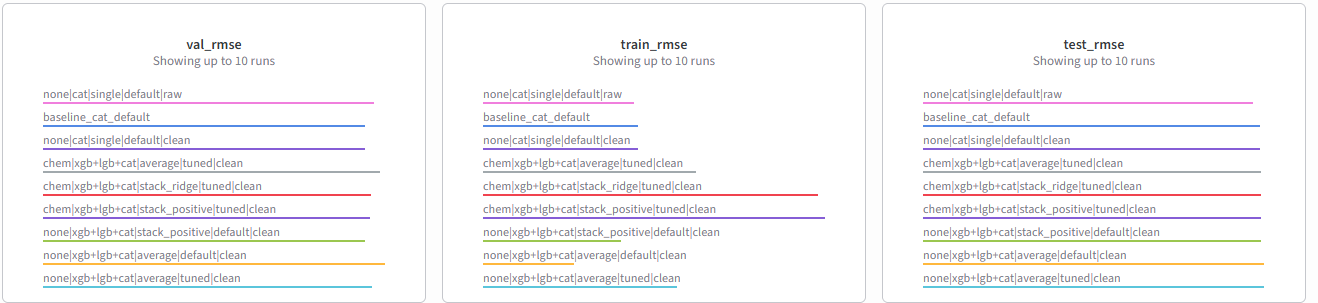

Challange prediction and csv creation

In [8]:
TEST_PATH = "../../challenge/TestData_Blinded_NoY.csv"
OUTPUT_PATH = "challenge.csv"

X, y = load_data()
X_blind = pd.read_csv(TEST_PATH, index_col="Name")[X.columns]

model = make_model("cat", "default")
model.fit(X, y)

submission = pd.DataFrame({"Y_pred": model.predict(X_blind)}, index=X_blind.index)
submission.index.name = "Name"

assert submission["Y_pred"].notna().all()
assert len(submission) == len(X_blind)

submission.to_csv(OUTPUT_PATH)
submission.head()

,Y_pred
Name,
T4,-0.035449
T15,0.553897
T24,-0.384573
T28,0.423627
T32,0.176444
